# Parte 2: Entrenamiento y comparación de modelos

**Notebook del Modelo A en Colab (ejecutada, con salidas):** [2a-modelo-custom](https://colab.research.google.com/drive/1jsKVLagYVW_ujwkjycdLnifEWf6rrMGf?usp=sharing)

Esta es la notebook de la entrega de la Parte 2. Reúne el trabajo de dos notebooks auxiliares, que están en el repo ejecutadas:

- [`2a-modelo-custom.ipynb`](2a-modelo-custom.ipynb): **Modelo A**, la CNN propia. Se entrenó en Colab (GPU T4), que es donde corren los experimentos y quedan sus checkpoints. Acá se muestran sus salidas y no se reentrena.
- [`2b-modelo-preentrenado.ipynb`](2b-modelo-preentrenado.ipynb): **Modelo B**, InsightFace `buffalo_l` sin reentrenar, con la evaluación de un solo modelo y sus lecturas en detalle.

Acá se recalculan los embeddings de **los dos modelos en la misma corrida** a partir de sus `.onnx` (los mismos archivos que carga la app) y se evalúan con el mismo protocolo, los mismos pares, la misma galería y la misma máquina. Toda la lógica está en `src/lib/` (`lib.evaluation`, `lib.dataset.clustering`, `lib.vision`); la notebook solo la llama.

**Para correrla:** las caras alineadas de la Parte 1 en `data/processed/aligned/` y los dos modelos en `models/`:
- `custom_cnn.onnx`: [link público](https://drive.google.com/file/d/1iWWYQ4wmxB1UdXM3lfTFq3anLCqIYvWS/view?usp=sharing).
- `w600k_r50.onnx`: viene en el paquete `buffalo_l` de InsightFace (`~/.insightface/models/buffalo_l/`).

## Equipo
- Lucas Ramirez — R4727/9 — @lucasramire (Modelo B, evaluación y Parte 3)
- Valentín Lujambio — L3417/7 — @valentinlujambio (Modelo A)

In [1]:
import base64
import json
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.dataset.clustering import default_algorithms, evaluate_clustering, project_tsne
from lib.dataset.faces import load_aligned, pose_angles
from lib.evaluation import (UNKNOWN, EmbeddingSet, best_scores, evaluate_identification, far_frr_curve, hardest_errors,
                            load_embeddings, make_pairs, most_confused, open_set_curve, rate_at_threshold, results_path,
                            save_embeddings, split_gallery, threshold_at_far, threshold_at_fpir, verification_metrics)
from lib.evaluation.cost import file_size_mb, ms_per_face, onnx_parameters
from lib.training.metrics import verification_score
from lib.vision import OnnxFaceEmbedder

CONFIG = json.loads((ROOT / "splits" / "config.json").read_text(encoding="utf-8"))
ALIGNED_ROOT = ROOT / CONFIG["aligned_root"]
SEED = CONFIG["seed"]
NB_2A = ROOT / "2a-modelo-custom.ipynb"

# Nombre en results/ → (etiqueta, archivo .onnx en models/)
MODELS = {
    "custom_cnn": ("Modelo A: CNN custom", ROOT / "models" / "custom_cnn.onnx"),
    "insightface_buffalo_l": ("Modelo B: InsightFace buffalo_l", ROOT / "models" / "w600k_r50.onnx"),
}
NAMES = {model: label for model, (label, _) in MODELS.items()}
splits = pd.read_csv(ROOT / "splits" / "splits.csv")
splits["split"].value_counts()

C:\Users\lucas\Documents\TUIA\IA 5.1 - Vision por Computadora\cv-venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


split
train          9006
val_open       2003
val_closed     1980
test_closed    1974
test_open      1900
Name: count, dtype: int64

In [2]:
def load_faces(rows: pd.DataFrame) -> list[np.ndarray]:
    """Caras alineadas en BGR, tal como las guardó la Parte 1."""
    return load_aligned(rows["aligned_path"], ALIGNED_ROOT)


def show_pairs(frame: pd.DataFrame, paths: np.ndarray, labels: np.ndarray, suptitle: str, ncols: int = 8) -> None:
    """Grilla de pares (i, j) con su score: dos imágenes por par."""
    n = 2 * len(frame)
    if n == 0:
        print(f"{suptitle}: ninguno")
        return
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.8, nrows * 2.1), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    images = load_aligned(np.ravel(np.c_[paths[frame["i"]], paths[frame["j"]]]), ALIGNED_ROOT)
    for k, (ax, image) in enumerate(zip(axes.flat, images)):
        row = frame.iloc[k // 2]
        position = row["i"] if k % 2 == 0 else row["j"]
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(labels[position] + (f"\nscore {row['score']:.3f}" if k % 2 else ""), fontsize=7)
    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


def show_saved_outputs(notebook: Path, snippet: str, last_lines: int | None = None) -> None:
    """Vuelve a mostrar las salidas guardadas de la celda de otra notebook cuyo código contiene `snippet`."""
    cell = next(c for c in json.loads(notebook.read_text(encoding="utf-8"))["cells"]
                if c["cell_type"] == "code" and snippet in "".join(c["source"]))
    for output in cell["outputs"]:
        data = output.get("data", {})
        if "image/png" in data:
            display(Image(base64.b64decode("".join(data["image/png"]))))
        elif "text/html" in data:
            display(HTML("".join(data["text/html"])))
        elif "text" in output or "text/plain" in data:
            lines = "".join(output.get("text") or data["text/plain"]).splitlines()
            print("\n".join(lines[-last_lines:] if last_lines else lines))

## 1. Modelo A: CNN custom (3.1)

Detalle completo, con el log de entrenamiento de cada época, en [`2a-modelo-custom.ipynb`](2a-modelo-custom.ipynb). Las tablas y curvas de esta sección son las salidas guardadas de esa notebook, ejecutada en Colab: entrenar los seis experimentos en esta máquina (GTX 1050) no cambiaría nada y llevaría horas.

**Enfoque:** clasificación + embedding (enfoque 1 del enunciado) como punto de partida, y después *fine-tuning* con margen angular ArcFace (enfoque 2). El embedding es la salida de 128 dimensiones previa a la cabeza, normalizada L2; la cabeza solo se usa para entrenar y no se exporta.

**Arquitectura** (`src/lib/models/custom_cnn.py`): ResNet chica de 4 etapas.

| Bloque | Salida | Detalle |
|---|---|---|
| Stem | 32×112×112 | conv 3×3 + BN + PReLU |
| Etapas 1 a 4 | 32×56², 64×28², 128×14², 256×7² | 2 bloques residuales por etapa, el primero con stride 2 |
| Embedding | 128 | BN → Dropout (0,2) → global average pooling → FC → BN |

- **Profundidad:** 4 etapas (el enunciado sugiere 4 a 6 bloques) llevan 112 → 7; los atajos residuales permiten 8 bloques sin problemas de gradiente.
- **BatchNorm** después de cada conv: estabiliza el entrenamiento desde cero y tolera lr altos.
- **Dropout** antes del FC: regulariza con solo ~110 imágenes por identidad.
- **Global average pooling:** el FC recibe 256 valores en vez de 7·7·256 = 12.544 (33 mil parámetros en vez de 1,6 millones); con pocos datos reduce el sobreajuste.
- **~2,8 M de parámetros**, entrada 112×112 RGB con `(x − 127,5) / 127,5`, la misma normalización que ArcFace (`InputNormalization`), así la app trata igual a los dos modelos.

**Datos:** `train` (9.006 imágenes de 80 personas) con la augmentation de la Parte 1; `val_closed` (mismas 80 personas) para las curvas de loss y accuracy; `val_open` (12 personas no vistas) para elegir el checkpoint y para el *early stopping*, porque la app tiene que reconocer a personas registradas después del entrenamiento. `test_open` y `test_closed` no se usan para elegir nada.

In [3]:
show_saved_outputs(NB_2A, "Parámetros del extractor", last_lines=1)
print("\nHiperparámetros de los experimentos:")
show_saved_outputs(NB_2A, "hparams.drop")

Parámetros del extractor: 2,831,616

Hiperparámetros de los experimentos:


name,exp1_softmax_sgd,exp2_softmax_adamw,exp3_arcface_sgd,exp4_arcface_finetune,exp5_arcface_ft_lr1e-3,exp6_normsoftmax_ft_lr1e-3
head,softmax,softmax,arcface,arcface,arcface,arcface
optimizer,sgd,adamw,sgd,sgd,sgd,sgd
lr,0.1,0.001,0.1,0.01,0.001,0.001
weight_decay,0.0005,0.0001,0.0005,0.0005,0.0005,0.0005
schedule,cosine,cosine,cosine,cosine,constant,constant
warmup_epochs,2,2,2,1,0,0
epochs,60,60,60,25,10,10
patience,10,10,15,10,10,10
scale,-,-,30.0,30.0,30.0,30.0
margin,-,-,0.5,0.5,0.5,0.0


**Hiperparámetros comunes:** cross-entropy sobre la cabeza (softmax o ArcFace con s = 30, m = 0,5), batch 128, SGD con momentum 0,9 y Nesterov (AdamW en el exp 2, como en la clase 4), schedule coseno con *warmup* lineal o lr constante en los controles, *weight decay* 5e-4, AMP en GPU y *early stopping* sobre el AUC de verificación en `val_open` (se guarda el `best.pt` de mayor AUC).

### Curvas de entrenamiento

Por experimento: loss y accuracy de train contra validación (`val_closed`) y AUC/EER de verificación en `val_open`. La línea punteada marca la mejor época. Con ArcFace la loss de train incluye el margen y la de validación no, así que su escala no se compara con la de softmax.

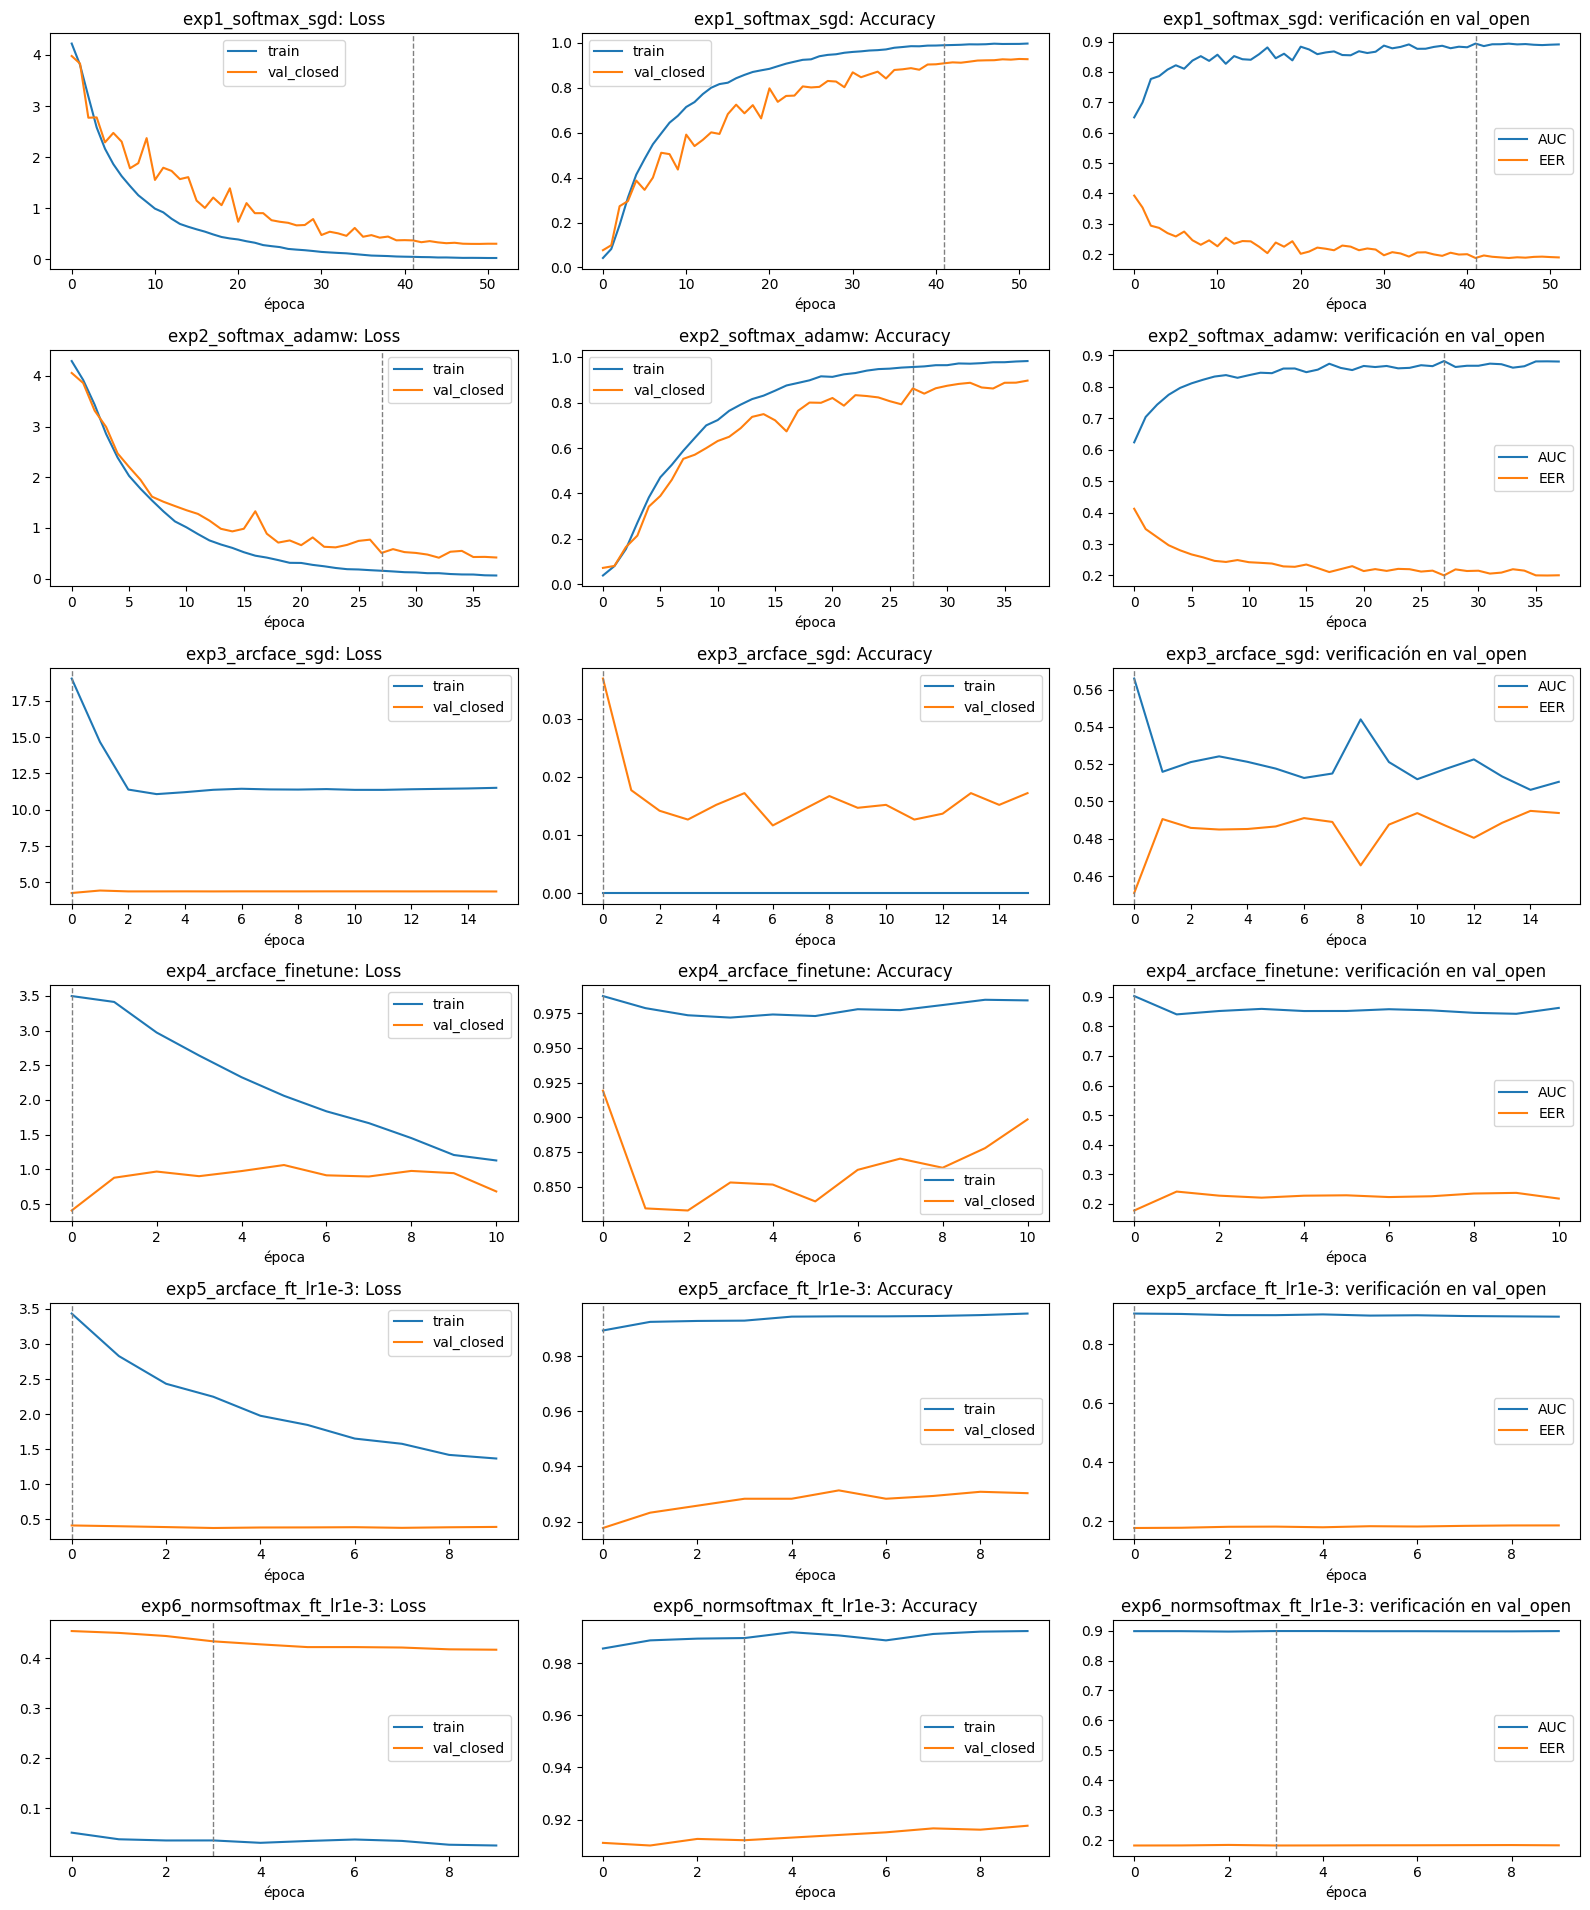

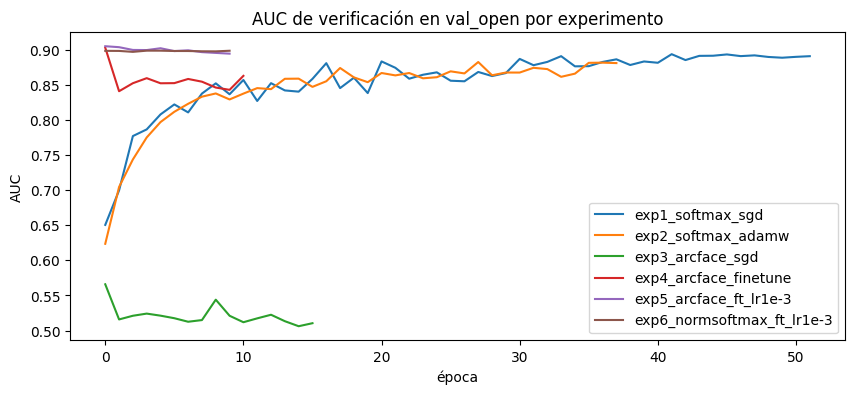

In [4]:
show_saved_outputs(NB_2A, "fig, axes = plt.subplots(len(histories)")

### Experimentos

Mejor época de cada corrida según el AUC en `val_open`.

In [5]:
show_saved_outputs(NB_2A, "BEST_EXPERIMENT = summary")

Elegido: exp5_arcface_ft_lr1e-3


,épocas,mejor época,lr,train_loss,train_acc,val_loss,val_acc,val_open_auc,val_open_eer
experimento,,,,,,,,,
exp1_softmax_sgd,52,41,0.0242,0.0473,0.9895,0.3693,0.9091,0.8934,0.1878
exp2_softmax_adamw,38,27,0.0006,0.1544,0.9580,0.5060,0.8636,0.8822,0.2001
exp3_arcface_sgd,16,0,0.0100,19.0343,0.0000,4.2684,0.0369,0.5659,0.4509
exp4_arcface_finetune,11,0,0.0010,3.4979,0.9874,0.4069,0.9192,0.9026,0.1776
exp5_arcface_ft_lr1e-3,10,0,0.0010,3.4334,0.9893,0.4150,0.9177,0.9047,0.1764
exp6_normsoftmax_ft_lr1e-3,10,3,0.0010,0.0354,0.9896,0.4341,0.9121,0.8984,0.1826


**Qué se probó, qué no funcionó y por qué** (conclusiones de la 2a):

| Exp | Qué | Resultado | Lectura |
|---|---|---|---|
| 1 | softmax + SGD, coseno desde lr 0,1 | AUC val_open 0,893 | Línea de base. **Sobreajuste:** train acc 0,99 contra 0,91 en `val_closed`, y el AUC en `val_open` se estanca mientras `val_closed` sigue mejorando: separa las 80 personas de train pero generaliza menos a personas nuevas. |
| 2 | softmax + AdamW | peor que el 1 | El *early stopping* cortó con lr ≈ 3,4e-4 y val acc todavía subiendo: no llegó a la fase de lr bajo del coseno, donde SGD logró su mejor época. |
| 3 | ArcFace desde cero | AUC ≈ 0,5 (azar) | **No convergió:** la loss queda trabada en ~11,4. Desde cero todos los ángulos están cerca de 90° y con m = 0,5 la clase correcta nunca supera a las demás. Falla conocida de ArcFace con pocos datos y sin preentrenamiento. |
| 4 | ArcFace *fine-tuning* desde el exp 1, coseno con lr 0,01 | mejor época: la 0 | Al subir el lr a 0,01 después del *warmup* el AUC cae y no se recupera: lr demasiado alto para *fine-tuning*. |
| 5 | control: ArcFace (m = 0,5), lr 0,001 constante | **AUC 0,905, EER 0,176** | **Elegido.** |
| 6 | control: igual que el 5 sin margen (m = 0) | AUC 0,898, EER 0,183 | Entrenar más con lr bajo explica parte de la mejora sobre el exp 1; el margen agrega otro ~0,006 de AUC, unas 3 veces el ruido entre corridas (~0,002). |

En los dos controles la mejor época es la primera o casi, y después el AUC baja: con 80 identidades, seguir ajustando a train no mejora la generalización a personas nuevas. Ese es el techo del Modelo A, y es la razón de fondo de lo que muestra la evaluación de la sección 3.

## 2. Modelo B: InsightFace `buffalo_l` (3.2)

Se usa como **extractor de embeddings, sin reentrenar**. El paquete tiene dos modelos ONNX, los mismos que usa la app:

| | Detector | Reconocedor |
|---|---|---|
| Archivo | `det_10g.onnx` | `w600k_r50.onnx` |
| Modelo | **SCRFD-10GF** (Guo et al., 2021) | **IResNet-50** entrenada con **ArcFace** (Deng et al., 2019) |
| Datos de entrenamiento | WIDER FACE | **WebFace600K**: subconjunto limpio de WebFace260M, unas 600 mil identidades y ~12 millones de imágenes |
| Entrada | imagen completa (redimensionada a 640×640) | cara alineada de 112×112, RGB, `(x − 127,5) / 127,5` |
| Salida | caja, score y 5 landmarks | embedding de **512** dimensiones |

- **Cómo se usa:** el detector y la alineación ya corrieron en la Parte 1 (2.4), con los mismos parámetros que usa `face_service.py`. Acá solo corre el reconocedor sobre las caras alineadas de `splits.csv`, con `OnnxFaceEmbedder` e `InputNormalization`, las mismas clases que la app. Para el Modelo A es igual: solo cambia el `.onnx`.
- **ArcFace:** clasificador sobre las identidades de entrenamiento con embeddings y pesos normalizados, y un margen angular de 0,5 rad sumado a la clase correcta. Obliga a que cada identidad quede compacta y lejos de las demás en coseno, también para personas que el modelo no vio. Es la misma pérdida que el exp 5 del Modelo A, pero con 600 mil identidades en vez de 80.
- **Licencia:** el código de InsightFace es MIT, pero los **pesos preentrenados son solo para investigación y uso no comercial**. Sirven para este trabajo; una app comercial necesitaría otra licencia o un modelo propio, como el A.

**Advertencia sobre las métricas.** WebFace260M se armó con fotos de celebridades de internet, igual que Pins: es muy probable que varias de nuestras 105 personas, incluidas las de `test_open`, estén entre las identidades con las que se entrenó. Además, ArcFace se usó en la Parte 1 para curar el dataset (duplicados, errores de etiqueta y outliers), así que se descartaron justamente las fotos que ArcFace no ubicaba bien. Las dos cosas favorecen al Modelo B: sus cifras son optimistas respecto de personas que realmente no vio.

### Extracción de embeddings de los dos modelos

Se calculan sobre todos los splits salvo `train` (7.857 caras), con el `.onnx` de cada modelo, y se guardan en `results/<modelo>/embeddings.npz` con el contrato común (`lib.evaluation.embedding_store`). Para el Modelo A se repite además la métrica de la 2a (AUC con todos los pares de `val_open`): si coincide, el `.onnx` publicado es el checkpoint elegido y el pipeline de esta máquina reproduce al de Colab.

In [6]:
eval_rows = splits[splits["split"] != "train"].reset_index(drop=True)
eval_faces = load_faces(eval_rows)
embedders = {model: OnnxFaceEmbedder(path) for model, (_, path) in MODELS.items()}
val_open = (eval_rows["split"] == "val_open").to_numpy()

rows = []
for model, embedder in embedders.items():
    embeddings = embedder.embed(eval_faces)
    save_embeddings(
        EmbeddingSet(
            model=model,
            paths=eval_rows["aligned_path"].to_numpy(),
            labels=eval_rows["identity"].to_numpy(),
            splits=eval_rows["split"].to_numpy(),
            embeddings=embeddings,
        ),
        results_path(ROOT, model),
    )
    check = verification_score(embeddings[val_open], eval_rows["identity"].to_numpy()[val_open])
    rows.append({"modelo": NAMES[model], "archivo": MODELS[model][1].name, "embeddings": embeddings.shape,
                 "norma L2 media": np.linalg.norm(embeddings, axis=1).mean(),
                 "AUC val_open (todos los pares)": check.auc, "EER val_open (todos los pares)": check.eer})
pd.DataFrame(rows).set_index("modelo").round(4)

,archivo,embeddings,norma L2 media,AUC val_open (todos los pares),EER val_open (todos los pares)
modelo,,,,,
Modelo A: CNN custom,custom_cnn.onnx,"(7857, 128)",1.0,0.9047,0.1765
Modelo B: InsightFace buffalo_l,w600k_r50.onnx,"(7857, 512)",1.0,1.0000,0.0020


**Lectura.** El Modelo A da AUC 0,9047 y EER 0,1765 en `val_open` con todos los pares, lo mismo que la 2a en Colab (0,905 y 0,176 para el exp 5). El `.onnx` publicado es el checkpoint elegido, y el preprocesamiento de esta máquina es el mismo que se usó para entrenar. Los dos modelos devuelven embeddings normalizados L2, como los guarda la app.

## 3. Evaluación (3.3)

Desde acá todo se calcula sobre los `.npz`, con las funciones de `lib.evaluation`, y es igual para los dos modelos: **los mismos pares, la misma galería y las mismas consultas**, porque dependen solo de las etiquetas y de la semilla. Lo único propio de cada modelo es su umbral, que se calibra con el mismo criterio en validación.

| Qué | Split | Por qué |
|---|---|---|
| Verificación (pares) | `test_open` | Identidades que el Modelo A nunca vio: es el escenario de la app, que registra personas nuevas. |
| Calibración del umbral | `val_open` (1:1) y `val_closed` + `val_open` (1:N) | El umbral no se calibra sobre el conjunto en el que se reporta. |
| Identificación | galería de `val_closed`, consultas de `test_closed`, desconocidos de `test_open` | Ver 3b. |
| Clustering | `test_open` y `test_closed` | |

In [7]:
emb_sets = {model: load_embeddings(results_path(ROOT, model)) for model in MODELS}
reference = next(iter(emb_sets.values()))
assert all((e.paths == reference.paths).all() for e in emb_sets.values()), "los .npz tienen que tener las mismas caras en el mismo orden"

SPLITS_EVAL = ["val_closed", "test_closed", "val_open", "test_open"]
parts = {model: {split: e.subset(split) for split in SPLITS_EVAL} for model, e in emb_sets.items()}
labels_of = {split: reference.subset(split).labels for split in SPLITS_EVAL}
paths_of = {split: reference.subset(split).paths for split in SPLITS_EVAL}
pd.DataFrame({NAMES[m]: {"dimensión": e.dim, **{s: len(p.labels) for s, p in parts[m].items()}} for m, e in emb_sets.items()})

,Modelo A: CNN custom,Modelo B: InsightFace buffalo_l
dimensión,128,512
val_closed,1980,1980
test_closed,1974,1974
val_open,2003,2003
test_open,1900,1900


### 3a. Verificación: ¿son la misma persona?

**5.000 pares positivos y 5.000 negativos** dentro de `test_open` (13 personas), y lo mismo en `val_open` para calibrar. Los positivos se reparten por igual entre identidades, para que las personas con más fotos no pesen más; los negativos son pares al azar de personas distintas. Con 5.000 negativos el FAR más chico medible es 2e-4, así que TAR@FAR = 1e-3 se apoya en 5 falsos positivos: tiene bastante varianza.

AUC     EER  umbral EER  \
Modelo A: CNN custom            val_open   0.8970  0.1850      0.2166   
                                test_open  0.8993  0.1820      0.2226   
Modelo B: InsightFace buffalo_l val_open   1.0000  0.0018      0.2289   
                                test_open  1.0000  0.0036      0.2009   

                                           TAR@FAR=0.01  TAR@FAR=0.001  
Modelo A: CNN custom            val_open         0.2828         0.1030  
                                test_open        0.3196         0.1528  
Modelo B: InsightFace buffalo_l val_open         0.9998         0.9976  
                                test_open        0.9990         0.9952

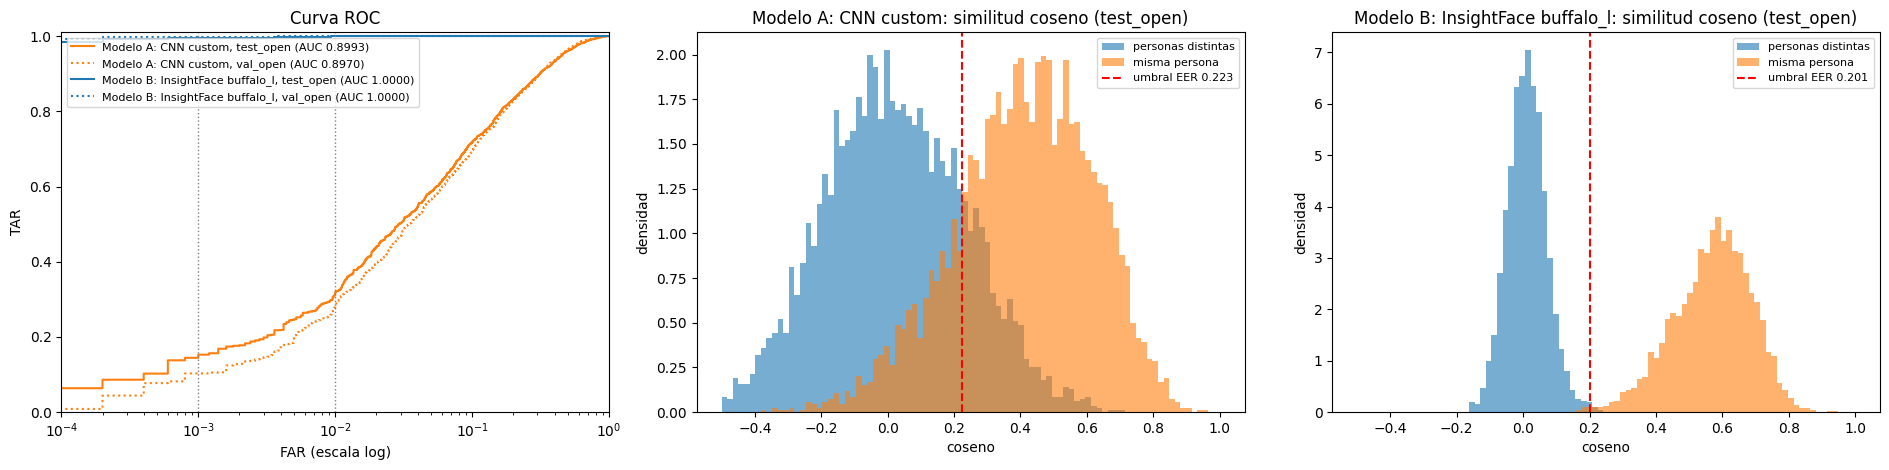

In [8]:
N_PAIRS = 5000
pairs = {split: make_pairs(labels_of[split], N_PAIRS, seed=SEED) for split in ["val_open", "test_open"]}
scores = {m: {split: p.scores(parts[m][split].embeddings) for split, p in pairs.items()} for m in MODELS}
verification = {m: {split: verification_metrics(scores[m][split], pairs[split].same) for split in pairs} for m in MODELS}
display(pd.DataFrame({(NAMES[m], split): r.summary() for m in MODELS for split, r in verification[m].items()}).T.round(4))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for m, color in zip(MODELS, ["tab:orange", "tab:blue"]):
    for split, ls in [("test_open", "-"), ("val_open", ":")]:
        r = verification[m][split]
        axes[0].plot(r.far, r.tar, color=color, ls=ls, label=f"{NAMES[m]}, {split} (AUC {r.auc:.4f})")
axes[0].set(xscale="log", xlim=(1e-4, 1), ylim=(0, 1.01), xlabel="FAR (escala log)", ylabel="TAR", title="Curva ROC")
for far in (1e-2, 1e-3):
    axes[0].axvline(far, color="gray", ls=":", lw=1)
axes[0].legend(fontsize=8)
bins = np.linspace(-0.5, 1, 90)
same = pairs["test_open"].same
for ax, m in zip(axes[1:], MODELS):
    s = scores[m]["test_open"]
    ax.hist(s[~same], bins=bins, alpha=0.6, density=True, label="personas distintas")
    ax.hist(s[same], bins=bins, alpha=0.6, density=True, label="misma persona")
    ax.axvline(verification[m]["test_open"].eer_threshold, color="red", ls="--",
               label=f"umbral EER {verification[m]['test_open'].eer_threshold:.3f}")
    ax.set(title=f"{NAMES[m]}: similitud coseno (test_open)", xlabel="coseno", ylabel="densidad")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.**
- **Modelo B:** separación casi perfecta. AUC 0,99996 (se ve 1,0000 al redondear), EER 0,36 %, TAR 99,9 % a FAR = 1e-2 y 99,5 % a FAR = 1e-3. Los histogramas casi no se superponen: los pares de personas distintas se concentran alrededor de 0 y los de la misma persona alrededor de 0,6.
- **Modelo A:** AUC 0,899 y EER 18,2 % en `test_open`. Ordena bien en promedio, pero los histogramas se superponen mucho: los negativos van de −0,5 a 0,7 y los positivos de −0,4 a 0,9. Donde más se nota es en la cola: **a FAR = 1e-3 acepta solo el 15 % de los pares de la misma persona** (32 % a FAR = 1e-2). En la curva ROC la TAR del A se desploma por debajo de FAR = 1e-1. Ese tramo es justamente el que importa en la app, donde cada desconocido se compara contra cientos de registros.
- **Validación y test se comportan igual** en los dos modelos (A: AUC 0,897 contra 0,899; B: EER 0,18 % contra 0,36 %): lo que se calibre en validación se traslada a test.
- El AUC del A con estos pares (0,897 en `val_open`) es algo menor que con todos los pares (0,905): acá los positivos se reparten por igual entre personas, y pesan más las que el modelo separa peor.
- **Cautela:** B está favorecido (sección 2), y TAR@FAR = 1e-3 se apoya en 5 falsos positivos de 5.000.

### 3c. Elección del umbral

Va antes que la identificación porque la identificación lo usa.

La app compara cada cara contra **todos** los registros de la base y se queda con el más parecido (`FaceService.identify`); si ese score queda debajo de `SIMILARITY_THRESHOLD`, devuelve `unknown`. Eso es **identificación 1:N**: un desconocido tiene N oportunidades de superar el umbral, una por registro. Por eso se comparan dos formas de calibrar, las dos en validación y para cada modelo:

- **1:1:** sobre los pares de `val_open`, el umbral del EER y el de FAR = 1e-3.
- **1:N:** una galería como la de la app (5 imágenes por persona de `val_closed`: 80 personas, 400 registros), con el resto de `val_closed` como consultas conocidas y todo `val_open` como desconocidos. Para cada umbral se mide la **DIR** (conocidos aceptados con la identidad correcta) y la **FPIR** (desconocidos aceptados como alguien). Se elige el umbral con **FPIR = 1 %**, el mismo criterio para los dos modelos.

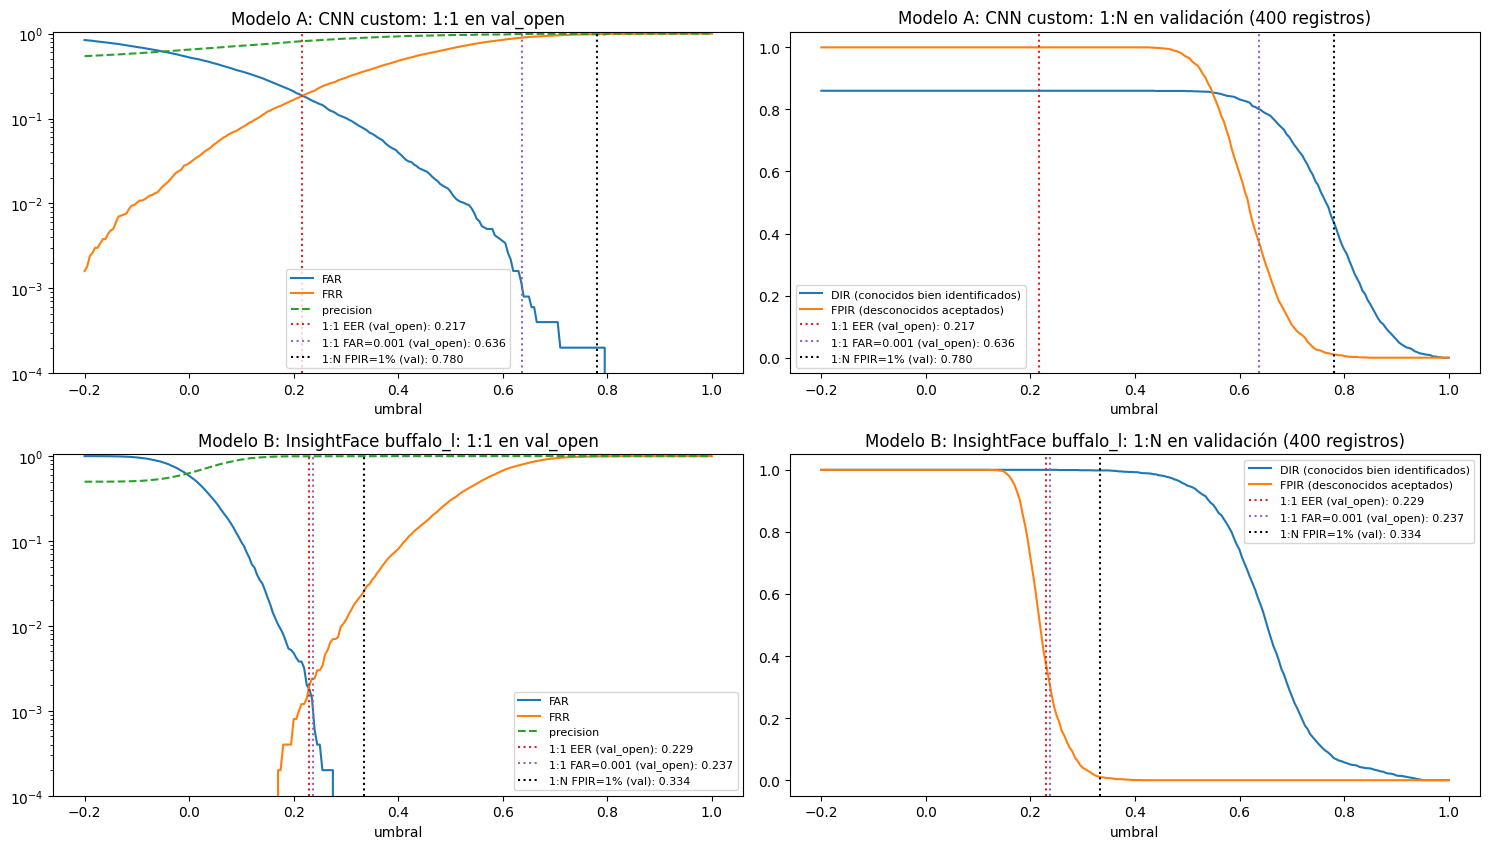

umbral  \
modelo                          criterio                           
Modelo A: CNN custom            1:1 EER (val_open)        0.2166   
                                1:1 FAR=0.001 (val_open)  0.6364   
                                1:N FPIR=1% (val)         0.7804   
Modelo B: InsightFace buffalo_l 1:1 EER (val_open)        0.2289   
                                1:1 FAR=0.001 (val_open)  0.2365   
                                1:N FPIR=1% (val)         0.3338   

                                                          FAR 1:1 (test_open)  \
modelo                          criterio                                        
Modelo A: CNN custom            1:1 EER (val_open)                     0.1884   
                                1:1 FAR=0.001 (val_open)               0.0008   
                                1:N FPIR=1% (val)                      0.0000   
Modelo B: InsightFace buffalo_l 1:1 EER (val_open)                     0.0006   
                                1:1 FAR=0.001 (val_open)               0.0004   
                                1:N FPIR=1% (val)                      0.0000   

                                                          FRR 1:1 (test_open)  \
modelo                          criterio                                        
Modelo A: CNN custom            1:1 EER (val_open)                     0.1754   
                                1:1 FAR=0.001 (val_open)               0.8614   
                                1:N FPIR=1% (val)                      0.9804   
Modelo B: InsightFace buffalo_l 1:1 EER (val_open)                     0.0064   
                                1:1 FAR=0.001 (val_open)               0.0072   
                                1:N FPIR=1% (val)                      0.0334   

                                                          FPIR 1:N (val)  \
modelo                          criterio                                   
Modelo A: CNN custom            1:1 EER (val_open)                1.0000   
                                1:1 FAR=0.001 (val_open)          0.3759   
                                1:N FPIR=1% (val)                 0.0100   
Modelo B: InsightFace buffalo_l 1:1 EER (val_open)                0.3834   
                                1:1 FAR=0.001 (val_open)          0.3120   
                                1:N FPIR=1% (val)                 0.0100   

                                                          DIR 1:N (val)  
modelo                          criterio                                 
Modelo A: CNN custom            1:1 EER (val_open)               0.8601  
                                1:1 FAR=0.001 (val_open)         0.8013  
                                1:N FPIR=1% (val)                0.4367  
Modelo B: InsightFace buffalo_l 1:1 EER (val_open)               1.0000  
                                1:1 FAR=0.001 (val_open)         1.0000  
                                1:N FPIR=1% (val)                0.9981

Modelo A: CNN custom: SIMILARITY_THRESHOLD = 0.780  (SIMILARITY_METRIC = cosine)
Modelo B: InsightFace buffalo_l: SIMILARITY_THRESHOLD = 0.334  (SIMILARITY_METRIC = cosine)


In [9]:
GALLERY_PER_IDENTITY = 5
TARGET_FAR = 1e-3
TARGET_FPIR = 0.01
CRITERION = f"1:N FPIR={TARGET_FPIR:.0%} (val)"
val_gallery, val_known = split_gallery(labels_of["val_closed"], GALLERY_PER_IDENTITY, seed=SEED)
gallery_labels = labels_of["val_closed"][val_gallery]

thresholds, open_set, rows = {}, {}, []
grid = np.linspace(-0.2, 1.0, 241)
fig, axes = plt.subplots(len(MODELS), 2, figsize=(15, 4.3 * len(MODELS)))
for row_axes, m in zip(axes, MODELS):
    p = parts[m]
    gallery_emb = p["val_closed"].embeddings[val_gallery]
    known_best, known_correct = best_scores(gallery_emb, gallery_labels, p["val_closed"].embeddings[val_known],
                                            labels_of["val_closed"][val_known])
    unknown_best, _ = best_scores(gallery_emb, gallery_labels, p["val_open"].embeddings)
    open_set[m] = (known_best, known_correct, unknown_best)
    thresholds[m] = {
        "1:1 EER (val_open)": verification[m]["val_open"].eer_threshold,
        f"1:1 FAR={TARGET_FAR:g} (val_open)": threshold_at_far(scores[m]["val_open"], pairs["val_open"].same, TARGET_FAR),
        CRITERION: threshold_at_fpir(unknown_best, TARGET_FPIR),
    }
    curve_11 = far_frr_curve(scores[m]["val_open"], pairs["val_open"].same, grid)
    curve_1n = open_set_curve(known_best, known_correct, unknown_best, grid)
    row_axes[0].plot(curve_11["umbral"], curve_11["FAR"], label="FAR")
    row_axes[0].plot(curve_11["umbral"], curve_11["FRR"], label="FRR")
    row_axes[0].plot(curve_11["umbral"], curve_11["precision"], label="precision", ls="--")
    row_axes[0].set(title=f"{NAMES[m]}: 1:1 en val_open", xlabel="umbral", yscale="log", ylim=(1e-4, 1.05))
    row_axes[1].plot(curve_1n["umbral"], curve_1n["DIR"], label="DIR (conocidos bien identificados)")
    row_axes[1].plot(curve_1n["umbral"], curve_1n["FPIR"], label="FPIR (desconocidos aceptados)")
    row_axes[1].set(title=f"{NAMES[m]}: 1:N en validación ({len(gallery_labels)} registros)", xlabel="umbral")
    for ax in row_axes:
        for (name, value), color in zip(thresholds[m].items(), ["tab:red", "tab:purple", "black"]):
            ax.axvline(value, color=color, ls=":", label=f"{name}: {value:.3f}")
        ax.legend(fontsize=8)
    for name, value in thresholds[m].items():
        rate = rate_at_threshold(scores[m]["test_open"], pairs["test_open"].same, value)
        rows.append({"modelo": NAMES[m], "criterio": name, "umbral": value,
                     "FAR 1:1 (test_open)": rate["FAR"], "FRR 1:1 (test_open)": rate["FRR"],
                     "FPIR 1:N (val)": float((unknown_best >= value).mean()),
                     "DIR 1:N (val)": float(((known_best >= value) & known_correct).mean())})
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).set_index(["modelo", "criterio"]).round(4))

THRESHOLD = {m: thresholds[m][CRITERION] for m in MODELS}
for m, value in THRESHOLD.items():
    print(f"{NAMES[m]}: SIMILARITY_THRESHOLD = {value:.3f}  (SIMILARITY_METRIC = cosine)")

**Decisión.**
- **Los umbrales 1:1 no sirven para la app, en ninguno de los dos modelos.** Con pares sueltos funcionan como se espera, pero en el escenario 1:N aceptan como alguien registrado a buena parte de los desconocidos de validación: B, el 38 % (EER) y el 31 % (FAR = 1e-3); A, el **100 %** con el umbral del EER y el 38 % con el de FAR = 1e-3. Cada desconocido se compara contra 400 registros y alcanza con que uno supere el umbral.
- **Modelo B:** `SIMILARITY_THRESHOLD = 0.334` (FPIR 1 % en validación) mantiene la DIR en 99,8 %: los conocidos tienen su mejor score muy por encima, y la curva DIR no baja hasta pasar 0,4. En 1:1 el costo es que la FRR de `test_open` sube de 0,6 % a 3,3 %, aceptable porque la app no compara pares sueltos.
- **Modelo A:** el mismo criterio lleva el umbral a **0,780**, y ahí la DIR cae a **44 %**: rechaza como `unknown` a más de la mitad de las personas registradas. En el gráfico 1:N, las curvas DIR y FPIR del A se cruzan cerca de 0,55, con 85 % en las dos: **no hay umbral que acepte a la mayoría de los conocidos y rechace a la mayoría de los desconocidos.** El mejor score de un desconocido contra 400 registros es tan alto como el de un conocido contra su propia galería.
- Es la misma conclusión de 3a, leída desde la app: lo que mata al Modelo A es la cola alta de los negativos, no el AUC.
- **Limitaciones:** el umbral depende del tamaño de la galería. Con más personas registradas, un desconocido tiene más chances de superarlo y habría que recalibrarlo. Con las 3 a 5 identidades de la demo (4.4), 0,334 es conservador.

### 3b. Identificación: ¿quién es?

- **Galería:** las mismas 5 imágenes por persona de `val_closed` de 3c (80 personas, 400 registros), como si se hubieran cargado con `/insert`. Se toman de `val_closed` y no de `test_closed` porque la Parte 1 asignó cada grupo de copias de una misma foto entero a un split: ninguna consulta tiene una copia suya en la galería.
- **Consultas conocidas:** todo `test_closed` (1.974 imágenes de las 80 personas).
- **Consultas desconocidas:** todo `test_open` (13 personas que no están en la galería); lo correcto es `unknown`.
- **Top-1 y Top-5** se miden sin umbral y solo con conocidos. **Precision, recall y F1 macro** se miden con el umbral de cada modelo, sobre conocidos y desconocidos, promediando sobre las 80 personas registradas: aceptar a un desconocido como alguien baja la precision de esa persona.
- **max** (el registro más parecido, como `identify` de la app) contra **mean** (promedio de los embeddings de cada persona, mejora opcional de 4.5).

In [10]:
identification = {
    m: {
        aggregate: evaluate_identification(
            parts[m]["val_closed"].embeddings[val_gallery], gallery_labels,
            parts[m]["test_closed"].embeddings, labels_of["test_closed"],
            THRESHOLD[m],
            parts[m]["test_open"].embeddings, labels_of["test_open"],
            aggregate=aggregate,
        )
        for aggregate in ["max", "mean"]
    }
    for m in MODELS
}
display(pd.DataFrame({(NAMES[m], f"galería: {a}"): r.summary() for m in MODELS for a, r in identification[m].items()}).round(4))

for m in MODELS:
    predictions = identification[m]["max"].predictions
    print(f"{NAMES[m]}: conocidos identificados como otra persona (verdadera → predicha)")
    display(most_confused(predictions[predictions["tipo"] == "conocido"], top=8))
    print(f"{NAMES[m]}: desconocidos aceptados como alguien registrado")
    display(most_confused(predictions[predictions["tipo"] == "desconocido"], top=8))

Modelo A: CNN custom                \
                                  galería: max galería: mean   
Top-1                                   0.8612        0.8967   
Top-5                                   0.9650        0.9726   
precision (macro)                       0.9553        0.9721   
recall (macro)                          0.3871        0.3966   
F1 (macro)                              0.5252        0.5424   
conocidos: correctos                    0.3896        0.3951   
conocidos: rechazados                   0.6079        0.6044   
conocidos: otra identidad               0.0025        0.0005   
desconocidos rechazados                 0.9895        0.9947   

                          Modelo B: InsightFace buffalo_l                
                                             galería: max galería: mean  
Top-1                                              1.0000        1.0000  
Top-5                                              1.0000        1.0000  
precision (macro)                                  0.9943        0.9992  
recall (macro)                                     0.9988        0.9993  
F1 (macro)                                         0.9962        0.9992  
conocidos: correctos                               0.9990        0.9995  
conocidos: rechazados                              0.0010        0.0005  
conocidos: otra identidad                          0.0000        0.0000  
desconocidos rechazados                            0.9921        0.9989

Modelo A: CNN custom: conocidos identificados como otra persona (verdadera → predicha)


,identidad,predicha,veces
0,Robert De Niro,Hugh Jackman,2
1,Danielle Panabaker,Sarah Wayne Callies,1
2,Hugh Jackman,Ben Affleck,1
3,Jeremy Renner,Tom Hardy,1


Modelo A: CNN custom: desconocidos aceptados como alguien registrado


,identidad,predicha,veces
0,Gwyneth Paltrow,Eliza Taylor,4
1,Dominic Purcell,Dwayne Johnson,3
2,Dominic Purcell,Neil Patrick Harris,2
3,Taylor Swift,Jennifer Lawrence,2
4,Elizabeth Lail,Sophie Turner,1
5,Emilia Clarke,Irina Shayk,1
6,Gwyneth Paltrow,Rebecca Ferguson,1
7,Jessica Barden,Maisie Williams,1


Modelo B: InsightFace buffalo_l: conocidos identificados como otra persona (verdadera → predicha)


,identidad,predicha,veces


Modelo B: InsightFace buffalo_l: desconocidos aceptados como alguien registrado


,identidad,predicha,veces
0,Emilia Clarke,Miley Cyrus,10
1,Emilia Clarke,melissa fumero,4
2,Emilia Clarke,alycia dabnem carey,1


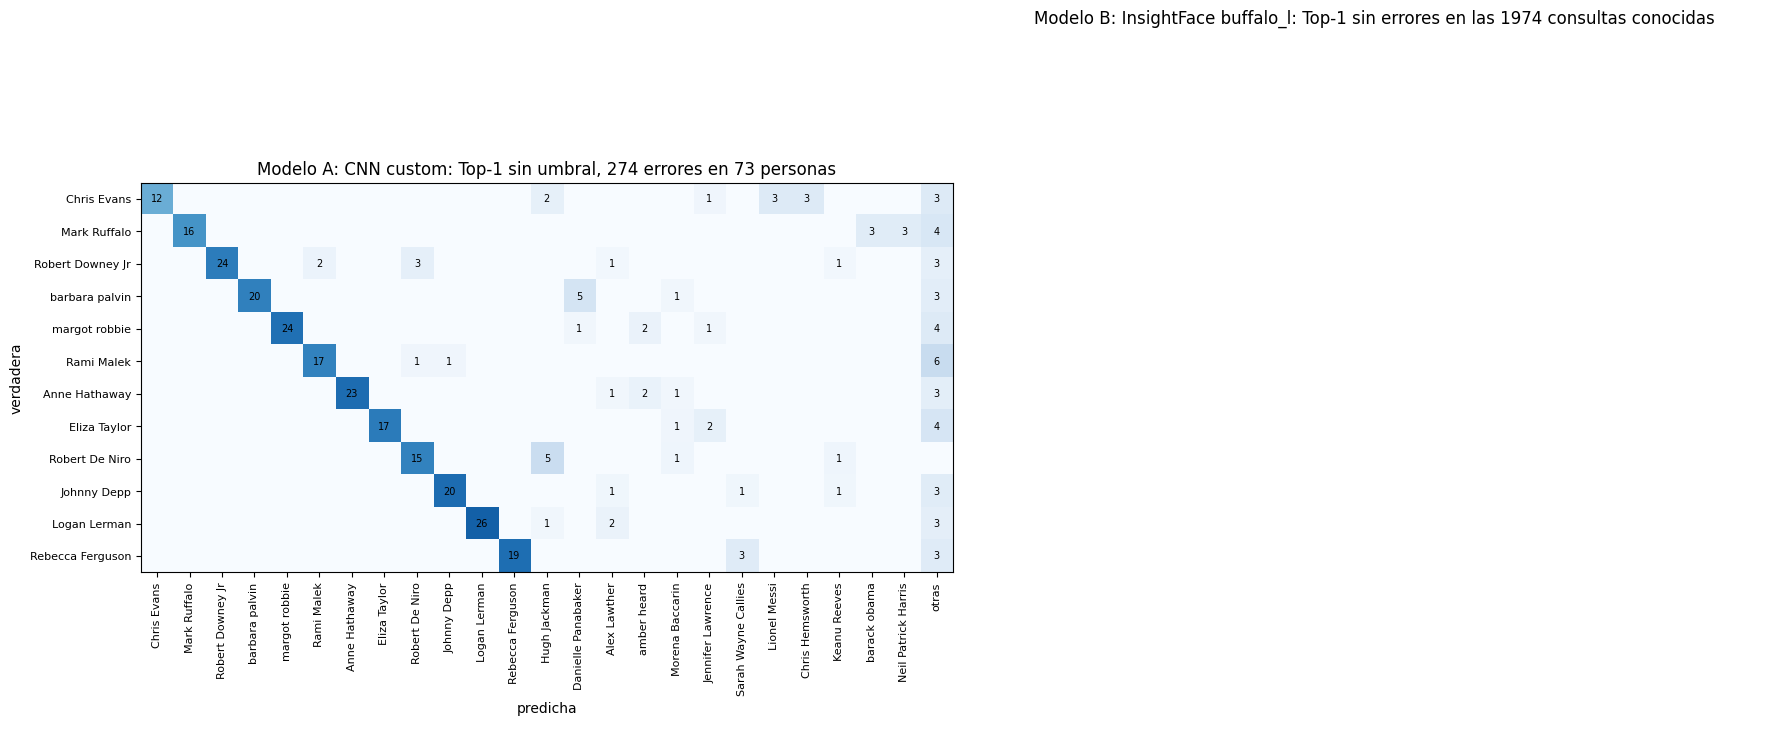

In [11]:
# Matriz de confusión del Top-1, sin umbral: con umbral casi todos los errores del Modelo A son rechazos
# (`unknown`, ya contados en la tabla) y no se ve con quién se confunde cada persona.
# Con 80 identidades no se lee entera: filas = las 12 personas con más errores; columnas = las personas con las
# que más se las confunde y "otras". Cada fila se colorea por su fracción; la diagonal son los aciertos.
TOP_CONFUSED = 12
fig, axes = plt.subplots(1, len(MODELS), figsize=(9 * len(MODELS), 7.5))
for ax, m in zip(axes, MODELS):
    top1 = evaluate_identification(parts[m]["val_closed"].embeddings[val_gallery], gallery_labels,
                                   parts[m]["test_closed"].embeddings, labels_of["test_closed"], -np.inf).predictions
    errors = top1[top1["verdadera"] != top1["predicha"]]
    if errors.empty:
        ax.set_axis_off()
        ax.set_title(f"{NAMES[m]}: Top-1 sin errores en las {len(top1)} consultas conocidas")
        continue
    people = errors["verdadera"].value_counts().index[:TOP_CONFUSED].tolist()
    rows_ = top1[top1["verdadera"].isin(people)]
    targets = people + [p for p in rows_.loc[rows_["verdadera"] != rows_["predicha"], "predicha"].value_counts().index
                        if p not in people][:TOP_CONFUSED]
    column = rows_["predicha"].where(rows_["predicha"].isin(targets), "otras")
    sub = pd.crosstab(rows_["verdadera"], column).reindex(index=people, columns=targets + ["otras"], fill_value=0)
    ax.imshow(sub / sub.to_numpy().sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(sub.shape[1]), sub.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(sub.shape[0]), sub.index, fontsize=8)
    for (r, c), v in np.ndenumerate(sub.to_numpy()):
        if v:
            ax.text(c, r, v, ha="center", va="center", fontsize=7)
    ax.set(title=f"{NAMES[m]}: Top-1 sin umbral, {len(errors)} errores en {errors['verdadera'].nunique()} personas",
           xlabel="predicha", ylabel="verdadera")
plt.tight_layout()
plt.show()

**Lectura.**
- **Modelo B:** Top-1 = Top-5 = 100 %. Con el umbral se acepta bien el 99,9 % de los conocidos (2 rechazos, ninguno confundido con otra persona) y se rechaza el 99,2 % de los desconocidos. Los 15 aceptados son todos fotos de Emilia Clarke, sobre todo tomadas por Miley Cyrus: uno de los diez pares de identidades más parecidos de 2.5.
- **Modelo A, sin umbral:** Top-1 86 % y Top-5 96,5 %. En *closed-set* ordena bastante bien: casi siempre la persona correcta está entre las 5 primeras. Los 274 errores Top-1 se reparten en 73 de las 80 personas, sin un par dominante, y casi siempre son del mismo género. Los más repetidos tienen rasgos gruesos en común: Robert De Niro → Hugh Jackman (5), Barbara Palvin → Danielle Panabaker (5), Mark Ruffalo → Barack Obama y Neil Patrick Harris.
- **Modelo A, con su umbral (0,780):** acepta bien solo el **39 %** de los conocidos, rechaza el 61 % y confunde el 0,25 %; rechaza el 98,9 % de los desconocidos. Por eso la precision macro es alta (0,955) y el recall muy bajo (0,387), con F1 0,525. La distancia entre el Top-1 (86 %) y el 39 % es lo que cuesta rechazar desconocidos con este modelo: lo que falla son los valores absolutos del score, no el orden.
- **Desconocidos aceptados por A:** Dominic Purcell (pelado) aceptado como Dwayne Johnson (pelado), y Gwyneth Paltrow como Eliza Taylor (las dos rubias). Es otra señal de que el embedding pesa mucho el pelo y el aspecto general.
- **max contra mean:** el promedio de los 5 registros ayuda a los dos: A pasa de 86,1 % a 89,7 % de Top-1 y B de 99,2 % a 99,9 % de desconocidos rechazados. Para usarlo en la app (mejora opcional de 4.5) habría que recalibrar el umbral con ese criterio.
- **Cautela:** fotos de una misma sesión pueden quedar en `val_closed` (galería) y en `test_closed` (consultas), lo que puede inflar algo el *closed-set* de los dos modelos (2.7).

### 3d. Clustering de embeddings

Proyección t-SNE y K-Means, aglomerativo y DBSCAN comparados con las etiquetas (ARI, NMI, silhouette coseno), con `lib.dataset.clustering`, igual que en 2.5. Sobre `test_open` (13 personas que el Modelo A no vio) y `test_closed` (80 personas). DBSCAN usa el `eps = 0,5` de 2.5, pensado para ArcFace: para el Modelo A no tiene por qué ser adecuado, y K-Means y el aglomerativo, que reciben la cantidad de personas, son la comparación justa.

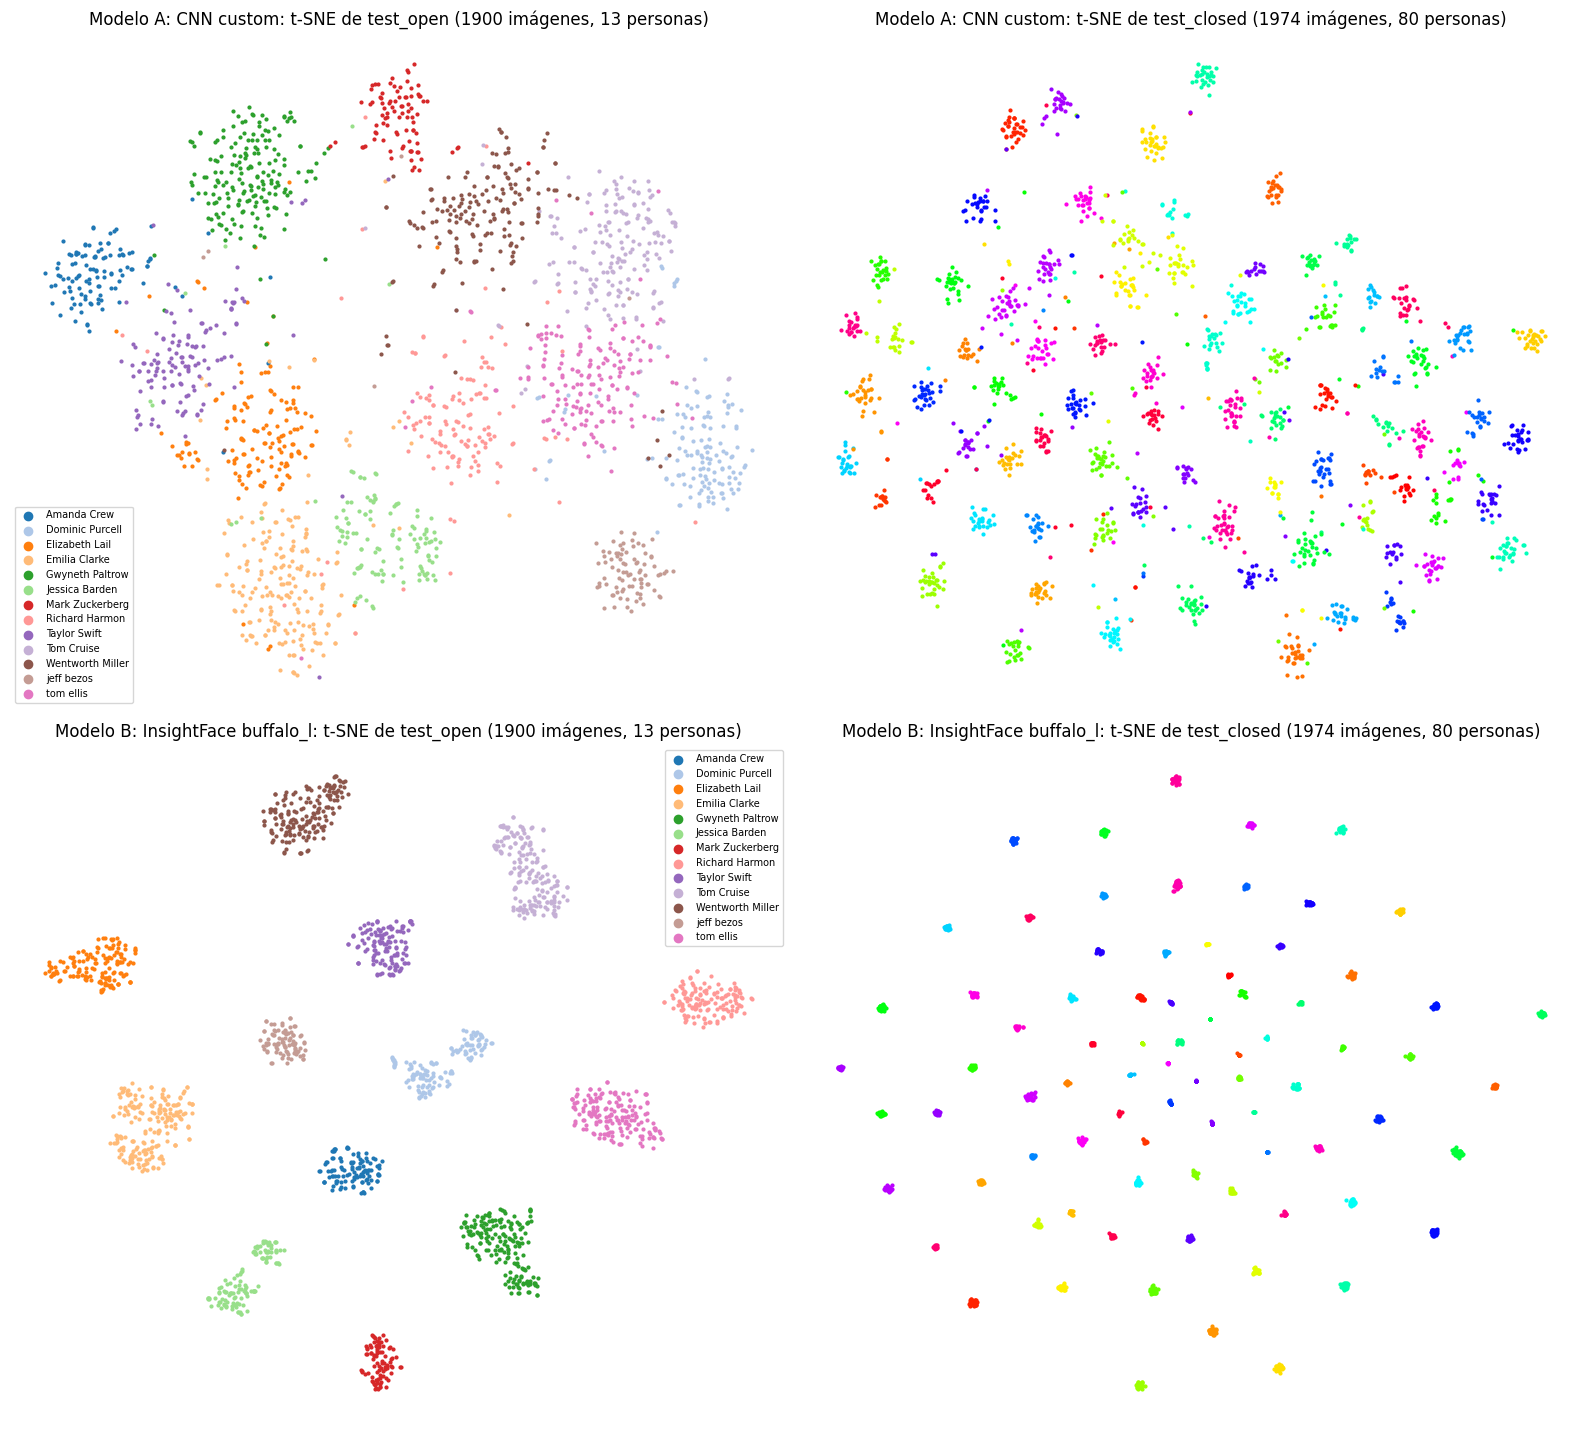

clusters  \
modelo                          split       algoritmo                                  
Modelo A: CNN custom            test_open   Etiquetas reales                      13   
                                            K-Means                               13   
                                            Aglomerativo (coseno, average)        13   
                                            DBSCAN (coseno, eps=0.5)               1   
                                test_closed Etiquetas reales                      80   
                                            K-Means                               80   
                                            Aglomerativo (coseno, average)        80   
                                            DBSCAN (coseno, eps=0.5)               1   
Modelo B: InsightFace buffalo_l test_open   Etiquetas reales                      13   
                                            K-Means                               13   
                                            Aglomerativo (coseno, average)        13   
                                            DBSCAN (coseno, eps=0.5)              13   
                                test_closed Etiquetas reales                      80   
                                            K-Means                               80   
                                            Aglomerativo (coseno, average)        80   
                                            DBSCAN (coseno, eps=0.5)              80   

                                                                            ruido  \
modelo                          split       algoritmo                               
Modelo A: CNN custom            test_open   Etiquetas reales                    0   
                                            K-Means                             0   
                                            Aglomerativo (coseno, average)      0   
                                            DBSCAN (coseno, eps=0.5)            0   
                                test_closed Etiquetas reales                    0   
                                            K-Means                             0   
                                            Aglomerativo (coseno, average)      0   
                                            DBSCAN (coseno, eps=0.5)            0   
Modelo B: InsightFace buffalo_l test_open   Etiquetas reales                    0   
                                            K-Means                             0   
                                            Aglomerativo (coseno, average)      0   
                                            DBSCAN (coseno, eps=0.5)           15   
                                test_closed Etiquetas reales                    0   
                                            K-Means                             0   
                                            Aglomerativo (coseno, average)      0   
                                            DBSCAN (coseno, eps=0.5)           39   

                                                                              ARI  \
modelo                          split       algoritmo                               
Modelo A: CNN custom            test_open   Etiquetas reales                1.000   
                                            K-Means                         0.738   
                                            Aglomerativo (coseno, average)  0.515   
                                            DBSCAN (coseno, eps=0.5)        0.000   
                                test_closed Etiquetas reales                1.000   
                                            K-Means                         0.790   
                                            Aglomerativo (coseno, average)  0.707   
                                            DBSCAN (coseno, eps=0.5)        0.000   
Modelo B: InsightFace buffalo_l test_open   Etiquetas reales                1.000   
                         

In [12]:
clustering = {}
fig, axes = plt.subplots(len(MODELS), 2, figsize=(16, 7.2 * len(MODELS)))
for row_axes, m in zip(axes, MODELS):
    for ax, split in zip(row_axes, ["test_open", "test_closed"]):
        part = parts[m][split]
        clustering[(NAMES[m], split)], _ = evaluate_clustering(part.embeddings, part.labels,
                                                               default_algorithms(seed=SEED, dbscan_eps=0.5))
        points = project_tsne(part.embeddings, seed=SEED)
        identities = np.unique(part.labels)
        colors = plt.cm.tab20(np.arange(len(identities)) % 20) if len(identities) <= 20 else \
            plt.cm.hsv(np.random.default_rng(SEED).permutation(len(identities)) / len(identities))
        for color, identity in zip(colors, identities):
            mask = part.labels == identity
            ax.scatter(points[mask, 0], points[mask, 1], s=4, color=color, label=identity if len(identities) <= 20 else None)
        ax.set_title(f"{NAMES[m]}: t-SNE de {split} ({len(part.labels)} imágenes, {len(identities)} personas)")
        ax.axis("off")
    row_axes[0].legend(fontsize=7, markerscale=3, loc="best")
plt.tight_layout()
plt.show()
clustering_table = pd.concat(clustering, names=["modelo", "split"]).droplevel(2).set_index("algoritmo", append=True)
clustering_table.round(3)

**Lectura.**
- **Modelo B:** en `test_open` las 13 personas forman islas separadas. K-Means y el aglomerativo recuperan la partición exacta (ARI 1,000) y el silhouette con las etiquetas es 0,515. En `test_closed` el aglomerativo vuelve a dar ARI 1,000.
- **Modelo A:** en `test_open` las personas forman grupos reconocibles en el t-SNE, pero con bordes difusos y puntos sueltos dentro de los grupos vecinos. El silhouette con las etiquetas reales es **0,178** (contra 0,515), K-Means llega a ARI 0,738 y el aglomerativo a 0,515: con *average linkage*, unos pocos puntos intermedios alcanzan para unir grupos.
- **El A separa mejor a las personas con las que se entrenó:** en `test_closed` (las 80 de train) el silhouette sube a 0,333 y el ARI de K-Means a 0,790; en el B pasa al revés (0,490 contra 0,515). Es la misma brecha de generalización de las curvas de la sección 1: el modelo aprendió a separar sus 80 identidades más que a describir caras en general. El t-SNE de `test_closed` del A se ve más ordenado de lo que dicen las métricas, porque t-SNE agranda la separación entre vecindarios locales.
- **DBSCAN con `eps = 0,5`** pone todo el Modelo A en un solo cluster: casi todas sus imágenes tienen vecinos a menos de 0,5 de distancia coseno. Es lo esperable con un `eps` calibrado para ArcFace, y por eso la comparación se hace con K-Means y el aglomerativo.

### 3e. Análisis de errores

Errores de verificación sobre los pares de `test_open`: **falsos positivos** (personas distintas aceptadas como la misma) y **falsos negativos** (la misma persona rechazada). Se usa el **umbral 1:1 del EER de `val_open`** de cada modelo y no el de la app: con el umbral 1:N, el Modelo A rechaza casi todos los pares positivos y no queda nada que analizar, y el B no tiene ningún falso positivo. El umbral del EER equilibra los dos tipos de error y trata igual a los dos modelos. Se muestran los negativos de score más alto y los positivos de score más bajo, que son los casos más difíciles.

Para las hipótesis se miden en cada imagen las condiciones que 2.5 señaló como difíciles: **pose** (indicador de yaw a partir de los landmarks de `splits.csv`), **blanco y negro** y **brillo** de la zona central de la cara.

Modelo A: CNN custom, umbral 1:1 EER (val_open) 0.217: 942 falsos positivos de 5000 negativos y 877 falsos negativos de 5000 positivos
Modelo A: CNN custom, umbral de la app (1:N) 0.780: 0 falsos positivos de 5000 negativos y 4902 falsos negativos de 5000 positivos
Modelo B: InsightFace buffalo_l, umbral 1:1 EER (val_open) 0.229: 3 falsos positivos de 5000 negativos y 32 falsos negativos de 5000 positivos
Modelo B: InsightFace buffalo_l, umbral de la app (1:N) 0.334: 0 falsos positivos de 5000 negativos y 167 falsos negativos de 5000 positivos


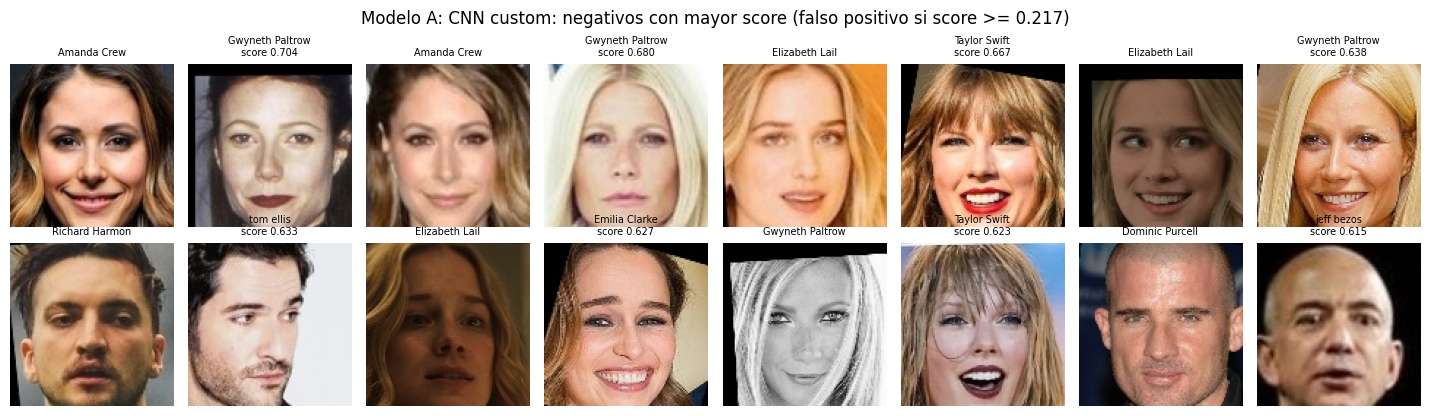

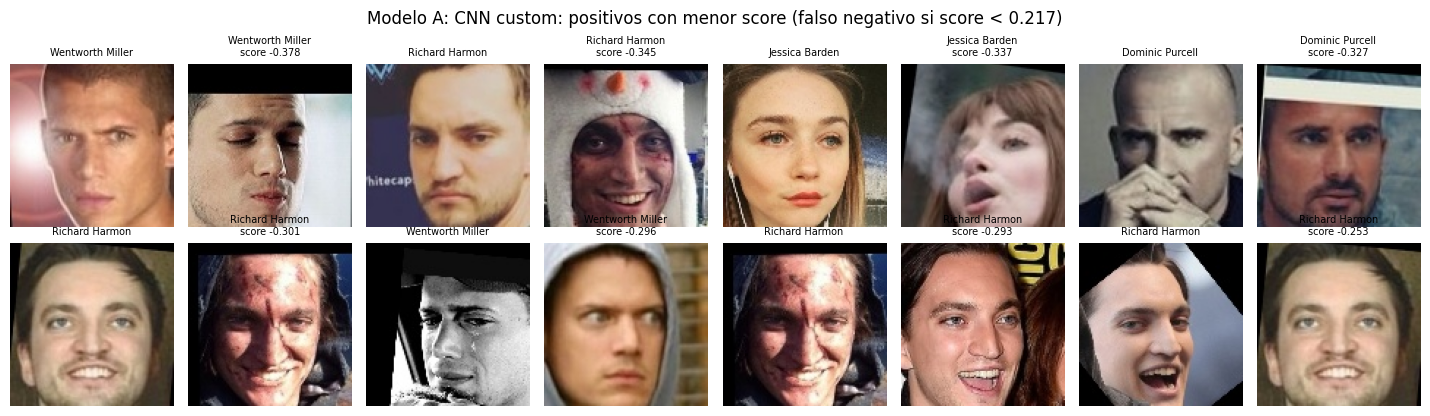

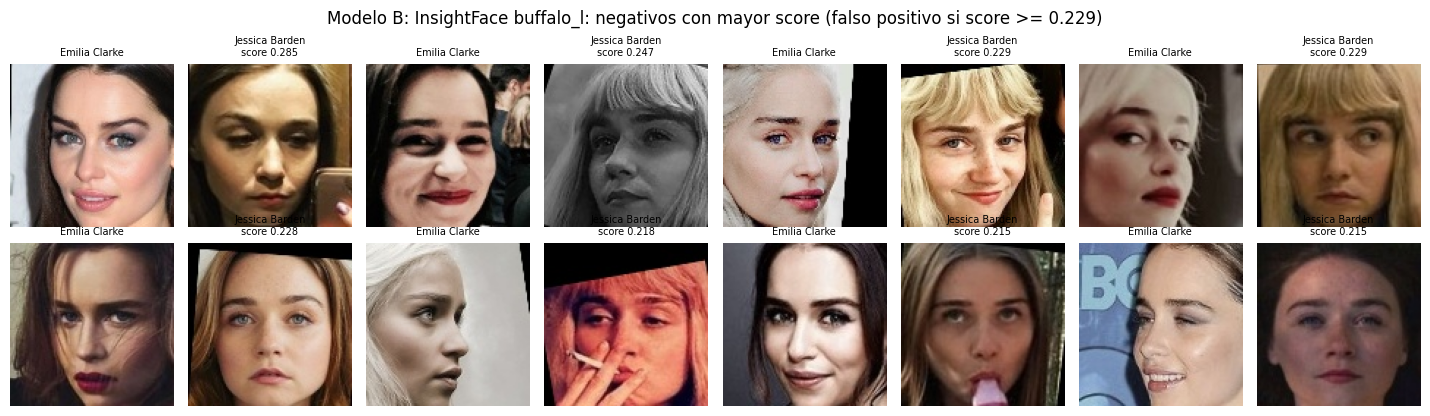

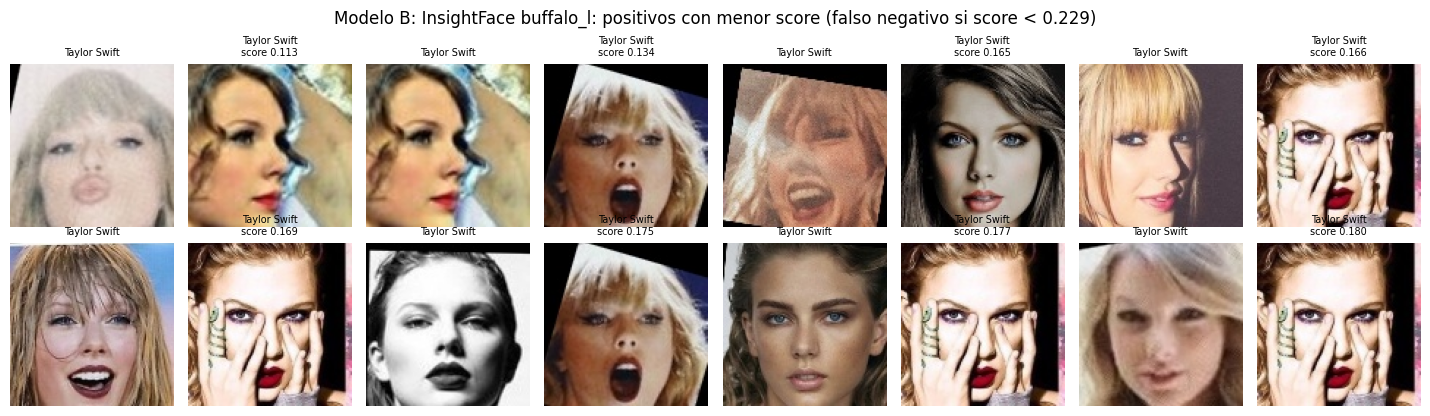

In [13]:
test_pairs = pairs["test_open"]
labels_test, paths_test = labels_of["test_open"], paths_of["test_open"]
ERROR_THRESHOLD = {m: thresholds[m]["1:1 EER (val_open)"] for m in MODELS}
errors = {}
for m in MODELS:
    for name, value in [("1:1 EER (val_open)", ERROR_THRESHOLD[m]), ("de la app (1:N)", THRESHOLD[m])]:
        fp, fn = hardest_errors(test_pairs, scores[m]["test_open"], value, top=10_000)
        print(f"{NAMES[m]}, umbral {name} {value:.3f}: {len(fp)} falsos positivos de {(~test_pairs.same).sum()} "
              f"negativos y {len(fn)} falsos negativos de {test_pairs.same.sum()} positivos")
    errors[m] = hardest_errors(test_pairs, scores[m]["test_open"], ERROR_THRESHOLD[m], top=10_000)
for m in MODELS:
    hardest_negatives, _ = hardest_errors(test_pairs, scores[m]["test_open"], -np.inf, top=8)
    _, hardest_positives = hardest_errors(test_pairs, scores[m]["test_open"], np.inf, top=8)
    show_pairs(hardest_negatives, paths_test, labels_test,
               f"{NAMES[m]}: negativos con mayor score (falso positivo si score >= {ERROR_THRESHOLD[m]:.3f})")
    show_pairs(hardest_positives, paths_test, labels_test,
               f"{NAMES[m]}: positivos con menor score (falso negativo si score < {ERROR_THRESHOLD[m]:.3f})")

In [14]:
# Condiciones de captura de cada imagen de test_open
meta = splits.set_index("aligned_path").loc[paths_test]
faces_test = load_aligned(paths_test, ALIGNED_ROOT)
center = (slice(36, 100), slice(28, 84))   # zona central de la cara, la misma de 2.3
conditions = pd.DataFrame({
    "|yaw|": pose_angles(meta)["yaw_proxy"].abs().to_numpy(),
    "blanco y negro": [bool(np.ptp(f.astype(int), axis=2).max() <= 8) for f in faces_test],
    "brillo central": [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)[center].mean() for f in faces_test],
})


def pair_conditions(frame: pd.DataFrame) -> pd.Series:
    """Peor condición de las dos imágenes de cada par, promediada sobre los pares."""
    i, j = frame["i"].to_numpy(), frame["j"].to_numpy()
    yaw = np.maximum(conditions["|yaw|"].to_numpy()[i], conditions["|yaw|"].to_numpy()[j])
    return pd.Series({
        "pares": len(frame),
        "|yaw| máx. del par": yaw.mean(),
        "% con perfil (|yaw| > 0,35)": 100 * (yaw > 0.35).mean(),
        "% con B/N": 100 * (conditions["blanco y negro"].to_numpy()[i] | conditions["blanco y negro"].to_numpy()[j]).mean(),
        "brillo mín. del par": np.minimum(conditions["brillo central"].to_numpy()[i], conditions["brillo central"].to_numpy()[j]).mean(),
    })


all_pairs = pd.DataFrame({"i": test_pairs.i, "j": test_pairs.j, "same": test_pairs.same})
table = {("todos", "positivos"): pair_conditions(all_pairs[all_pairs["same"]]),
         ("todos", "negativos"): pair_conditions(all_pairs[~all_pairs["same"]])}
for m in MODELS:
    fp, fn = errors[m]
    for name, frame in [("falsos negativos", fn), ("falsos positivos", fp)]:
        if len(frame):
            table[(NAMES[m], name)] = pair_conditions(frame)
display(pd.DataFrame(table).round(2))

# Tasa de falsos negativos por persona (sobre sus pares positivos) y personas más involucradas en falsos positivos
positives = all_pairs[all_pairs["same"]]
per_person = {}
for m in MODELS:
    fp, fn = errors[m]
    per_person[(NAMES[m], "% FN de sus positivos")] = (100 * pd.Series(labels_test[fn["i"]]).value_counts()
                                                       / pd.Series(labels_test[positives["i"]]).value_counts())
    per_person[(NAMES[m], "pares FP en que aparece")] = pd.concat([pd.Series(labels_test[fp["i"]]),
                                                                   pd.Series(labels_test[fp["j"]])]).value_counts()
display(pd.DataFrame(per_person).fillna(0).sort_values(list(per_person)[0], ascending=False).round(1))

todos           Modelo A: CNN custom  \
                            positivos negativos     falsos negativos   
pares                         5000.00   5000.00               877.00   
|yaw| máx. del par               0.22      0.23                 0.27   
% con perfil (|yaw| > 0,35)     17.12     17.10                25.20   
% con B/N                        9.22      9.84                11.06   
brillo mín. del par            116.86    114.64               107.44   

                                             Modelo B: InsightFace buffalo_l  \
                            falsos positivos                falsos negativos   
pares                                 942.00                           32.00   
|yaw| máx. del par                      0.23                            0.33   
% con perfil (|yaw| > 0,35)            17.20                           34.38   
% con B/N                               9.77                            9.38   
brillo mín. del par                   115.95                          129.29   

                                              
                            falsos positivos  
pares                                   3.00  
|yaw| máx. del par                      0.22  
% con perfil (|yaw| > 0,35)             0.00  
% con B/N                              33.33  
brillo mín. del par                   109.93

Modelo A: CNN custom                          \
                 % FN de sus positivos pares FP en que aparece   
Wentworth Miller                  36.1                     158   
Richard Harmon                    35.6                     140   
Jessica Barden                    27.9                     123   
tom ellis                         20.8                     157   
Tom Cruise                        20.1                     207   
Taylor Swift                      18.2                     137   
Emilia Clarke                     16.9                     156   
Dominic Purcell                   13.5                     143   
Elizabeth Lail                    13.5                     169   
Mark Zuckerberg                    8.8                     130   
jeff bezos                         7.5                      87   
Amanda Crew                        6.2                      97   
Gwyneth Paltrow                    2.9                     180   

                 Modelo B: InsightFace buffalo_l                          
                           % FN de sus positivos pares FP en que aparece  
Wentworth Miller                             0.0                     0.0  
Richard Harmon                               0.0                     0.0  
Jessica Barden                               0.8                     3.0  
tom ellis                                    0.3                     0.0  
Tom Cruise                                   0.3                     0.0  
Taylor Swift                                 6.5                     0.0  
Emilia Clarke                                0.0                     3.0  
Dominic Purcell                              0.5                     0.0  
Elizabeth Lail                               0.0                     0.0  
Mark Zuckerberg                              0.0                     0.0  
jeff bezos                                   0.0                     0.0  
Amanda Crew                                  0.0                     0.0  
Gwyneth Paltrow                              0.0                     0.0

**Lectura.** Con el umbral del EER de cada modelo, en `test_open`:
- **Modelo B: 3 falsos positivos y 32 falsos negativos de 5.000.** Los 3 falsos positivos son Emilia Clarke contra Jessica Barden: actrices de edad, pelo y rasgos parecidos, uno de los pares más cercanos de 2.5. Los falsos negativos tienen el doble de caras de perfil que el total de positivos (34 % contra 17 %) y se concentran en Taylor Swift (6,5 % de sus pares). El detalle, con oclusiones, baja resolución y un posible error de etiqueta, está en la 2b (3e).
- **Modelo A: 942 falsos positivos y 877 falsos negativos de 5.000.** No están concentrados en pocas personas: cada una aparece en 87 a 207 falsos positivos, y la tasa de falsos negativos va del 3 % (Gwyneth Paltrow) al 36 % (Wentworth Miller y Richard Harmon).
- **Hipótesis para los falsos positivos del A: parecido grueso.** Las condiciones de captura de sus falsos positivos son las de un negativo cualquiera (17 % de perfil, 10 % en blanco y negro, mismo brillo), así que no los explica la foto. En la grilla, los negativos de score más alto (0,6 a 0,7) son siempre del mismo género y con el mismo estilo: rubias sonriendo (Amanda Crew y Gwyneth Paltrow, Elizabeth Lail y Taylor Swift), hombres de barba y pelo oscuro, hombres pelados (Dominic Purcell y Jeff Bezos). El embedding codifica género, color y forma del pelo, expresión e iluminación más que los rasgos que identifican a una persona. Con 80 identidades esos atributos alcanzan para separar train, pero no para distinguir a personas nuevas que se parecen.
- **Hipótesis para los falsos negativos del A: la condición de captura.** Acá sí cambian las condiciones: el 25 % tiene una cara de perfil (contra 17 % del total), el brillo mínimo baja de 117 a 107 y el blanco y negro sube de 9 % a 11 %. Los positivos de peor score llegan a −0,38: el modelo ve a la misma persona como opuesta. Son casos de **oclusión** (capucha, gorro de muñeco de nieve, manos sobre la cara, pelo y humo sobre la cara), **pintura facial**, **iluminación fuerte** (un destello de lente), **blanco y negro** y **rotación grande**. El B es mucho más robusto a todo eso: lo vio en 12 millones de imágenes. La augmentation de la Parte 1 simula algo de esto, pero en chico: un solo rectángulo negro de 15 a 30 % del lado, rotaciones de ±10° y escala de grises en el 10 % de las imágenes. No reproduce una capucha, unas manos o un perfil real.
- **Pocas fotos explican muchos errores:** la misma foto de Richard Harmon pintado aparece en varios de los peores pares, igual que en el B pasaba con unas pocas fotos difíciles.
- **Para la app:** con cualquiera de los dos modelos conviene registrar varias fotos por persona, frontales, bien iluminadas y sin oclusiones.

### 3f. Costo computacional

Los dos reconocedores en la **misma corrida y la misma máquina** (CPU, `CPUExecutionProvider`), sobre las mismas 200 caras: **de a una** (el caso de la app, que procesa cada cara por separado) y en lotes de 64. No incluye la detección (SCRFD), que es la misma para los dos.

In [15]:
import platform

timing_faces = load_faces(eval_rows.sample(200, random_state=SEED))
cost = pd.DataFrame({
    m: {
        "parámetros (M)": onnx_parameters(path) / 1e6,
        "tamaño (MB)": file_size_mb(path),
        "dimensión del embedding": embedders[m].dim,
        "ms/rostro en CPU (lote 1)": ms_per_face(embedders[m], timing_faces, batch_size=1),
        "ms/rostro en CPU (lote 64)": ms_per_face(embedders[m], timing_faces, batch_size=64),
    }
    for m, (_, path) in MODELS.items()
}).rename(columns=NAMES)
print("CPU:", platform.processor())
cost.assign(**{"B / A": cost[NAMES["insightface_buffalo_l"]] / cost[NAMES["custom_cnn"]]}).round(2)

CPU: AMD64 Family 23 Model 96 Stepping 1, AuthenticAMD


,Modelo A: CNN custom,Modelo B: InsightFace buffalo_l,B / A
parámetros (M),2.83,43.59,15.40
tamaño (MB),10.81,166.31,15.39
dimensión del embedding,128.00,512.00,4.00
ms/rostro en CPU (lote 1),4.29,39.07,9.10
ms/rostro en CPU (lote 64),5.29,37.84,7.15


**Lectura.**
- **El Modelo A es mucho más liviano:** 2,8 M de parámetros y 10,8 MB contra 43,6 M y 166 MB (15 veces menos), y embeddings de 128 dimensiones contra 512 (4 veces menos espacio por registro en pgvector).
- **Es unas 9 veces más rápido:** 4,3 ms por rostro contra 39 ms de a una cara. Los lotes de 64 casi no cambian nada, porque onnxruntime ya reparte una sola cara entre todos los núcleos.
- **Los dos alcanzan para la app:** con 39 ms, el B procesa unas 25 caras por segundo, y la app reconoce una imagen por pedido. El costo del B es real (para un celular o una Raspberry Pi pesaría), pero en este caso de uso no decide la elección.
- La medición depende de la carga de la máquina: en otra corrida de la 2b el B tardó entre 46 y 96 ms. Por eso se miden los dos en la misma corrida; la relación de ~9 veces es más estable que los valores absolutos.

## 4. Comparación y elección final (3.4)

Todas las métricas de la sección 3 en una tabla. Verificación sobre `test_open`; identificación con la galería de `val_closed`, consultas de `test_closed` y `test_open` y el umbral de cada modelo; clustering con K-Means y aglomerativo.

In [16]:
def model_summary(m: str) -> dict[str, float]:
    ident = identification[m]["max"]
    known_best, known_correct, unknown_best = open_set[m]
    clust = {split: clustering[(NAMES[m], split)].set_index("algoritmo") for split in ["test_open", "test_closed"]}
    agglomerative = "Aglomerativo (coseno, average)"
    return {
        "verificación: AUC": verification[m]["test_open"].auc,
        "verificación: EER": verification[m]["test_open"].eer,
        "verificación: TAR@FAR=1e-2": verification[m]["test_open"].tar_at_far[1e-2],
        "verificación: TAR@FAR=1e-3": verification[m]["test_open"].tar_at_far[1e-3],
        "umbral (1:N, FPIR 1 % en val)": THRESHOLD[m],
        "identificación: Top-1": ident.top1,
        "identificación: Top-5": ident.top5,
        "identificación: precision (macro)": ident.precision,
        "identificación: recall (macro)": ident.recall,
        "identificación: F1 (macro)": ident.f1,
        "conocidos aceptados con la identidad correcta": ident.known_accepted_correct,
        "desconocidos rechazados": ident.unknown_rejected,
        "DIR 1:N en val con el umbral": float(((known_best >= THRESHOLD[m]) & known_correct).mean()),
        "silhouette test_open (etiquetas)": clust["test_open"].loc["Etiquetas reales", "silhouette"],
        "ARI K-Means test_open": clust["test_open"].loc["K-Means", "ARI"],
        "ARI aglomerativo test_open": clust["test_open"].loc[agglomerative, "ARI"],
        "ARI K-Means test_closed": clust["test_closed"].loc["K-Means", "ARI"],
        "ARI aglomerativo test_closed": clust["test_closed"].loc[agglomerative, "ARI"],
        **cost[NAMES[m]].to_dict(),
    }


comparison = pd.DataFrame({NAMES[m]: model_summary(m) for m in MODELS})
for m in MODELS:
    summary_path = results_path(ROOT, m).with_name("summary.json")
    summary_path.write_text(comparison[NAMES[m]].to_json(indent=2, force_ascii=False), encoding="utf-8")
comparison.round(4)

,Modelo A: CNN custom,Modelo B: InsightFace buffalo_l
verificación: AUC,0.8993,1.0000
verificación: EER,0.1820,0.0036
verificación: TAR@FAR=1e-2,0.3196,0.9990
verificación: TAR@FAR=1e-3,0.1528,0.9952
"umbral (1:N, FPIR 1 % en val)",0.7804,0.3338
identificación: Top-1,0.8612,1.0000
identificación: Top-5,0.9650,1.0000
identificación: precision (macro),0.9553,0.9943
identificación: recall (macro),0.3871,0.9988
identificación: F1 (macro),0.5252,0.9962


### Conclusión: se elige el Modelo B (InsightFace `buffalo_l`)

| Criterio | Modelo A: CNN custom | Modelo B: InsightFace `buffalo_l` |
|---|---|---|
| Verificación (`test_open`) | AUC 0,899, EER 18,2 %, TAR@FAR=1e-3 15 % | AUC 0,99996, EER 0,36 %, TAR@FAR=1e-3 99,5 % |
| Identificación con el umbral de la app | 39 % de conocidos bien identificados, F1 0,525 | 99,9 % de conocidos bien identificados, F1 0,996 |
| Desconocidos rechazados | 98,9 % | 99,2 % |
| Clustering (`test_open`) | silhouette 0,178, ARI K-Means 0,738 | silhouette 0,515, ARI 1,000 |
| Costo | 2,8 M parámetros, 10,8 MB, 4,3 ms/rostro | 43,6 M parámetros, 166 MB, 39 ms/rostro |
| Licencia | propia | pesos solo para uso no comercial / investigación |
| Integración | `.onnx` propio, 128-d | `.onnx` del mismo paquete que el detector, 512-d |

**Por qué B.**
- **Desempeño:** es la diferencia decisiva. Con el umbral que exige la app para rechazar desconocidos, el Modelo A reconoce a menos de la mitad de las personas registradas (3c, 3b). Para la app, eso equivale a no funcionar.
- **Costo:** el A es 15 veces más chico y 9 veces más rápido, pero los 39 ms del B entran de sobra en una app que procesa una imagen por pedido.
- **Licencia:** es la contra del B. Los pesos son no comerciales, válidos para este trabajo académico; un producto comercial tendría que entrenar su propio modelo (el camino del A, con muchos más datos) o licenciar uno.
- **Integración:** la más simple. El detector (`det_10g.onnx`) es del mismo paquete y ya lo necesita la app para detectar y alinear; el reconocedor espera exactamente la alineación de 5 puntos y la normalización que usa todo el pipeline.
- **Cautela:** las métricas del B son optimistas (las celebridades de Pins probablemente estén en WebFace600K, y ArcFace se usó para curar el dataset). Con personas realmente nuevas va a rendir algo peor, pero la distancia con el A es demasiado grande para que eso cambie la elección.

**Por qué el Modelo A rinde menos.**
1. **Datos, ante todo.** El A vio 9.006 imágenes de 80 personas; el B, ~12 millones de 600 mil. Para que un embedding generalice a caras nuevas tiene que haber visto variación de identidad, y 80 personas no cubren el espacio de caras. Por eso aprende atajos que alcanzan para separar train (género, pelo, expresión, iluminación; 3e) y que no sirven con personas nuevas que se parecen.
2. **Sobreajuste a las identidades de entrenamiento.** Train acc 0,99 contra 0,91 en `val_closed`; el AUC en `val_open` se estanca mientras `val_closed` sigue mejorando (sección 1); el silhouette es más alto en `test_closed` (0,333) que en `test_open` (0,178).
3. **La pérdida métrica quedó a medio camino.** ArcFace desde cero no convergió con tan pocos datos (exp 3). El margen solo entró como *fine-tuning* corto, que agregó ~0,01 de AUC: la mejor época fue la primera.
4. **El *open-set* exige scores calibrados, no solo ordenados.** El A ordena razonablemente bien (Top-1 86 %, Top-5 96,5 %), pero sus negativos llegan a 0,7 de coseno, y entre cientos de registros siempre aparece alguno que supera cualquier umbral razonable. El AUC (0,90) esconde ese problema; TAR@FAR = 1e-3 y la DIR con FPIR fijo lo muestran.
5. **Capacidad y robustez:** 2,8 M de parámetros contra 43,6 M, y una augmentation que simula oclusiones y cambios de pose chicos, no los de las fotos donde más falla (3e).

**Qué mejoraría el Modelo A**, en orden de impacto esperado: entrenar con un dataset de miles de identidades (CASIA-WebFace, VGGFace2 o un subconjunto de WebFace); partir de un backbone preentrenado (ResNet-18 o MobileNet de ImageNet, la opción de 3.1); ArcFace o CosFace con un margen que crezca de a poco desde 0, para que converja desde cero; oclusiones más grandes y realistas en la augmentation (manos, anteojos y gorros sintéticos); y elegir el checkpoint por TAR a FAR bajo en vez de AUC, que es lo que importa para la app.

## 5. Exportación del modelo (3.5)

Los dos modelos se exportan en **ONNX** y la app los carga con `onnxruntime.InferenceSession`, sin depender del código de la clase. Ninguno se versiona (`*.onnx` está en el `.gitignore`).

| | Modelo A | Modelo B (elegido) |
|---|---|---|
| Archivo | `models/custom_cnn.onnx` | `models/w600k_r50.onnx` (+ `models/det_10g.onnx`, el detector) |
| Cómo se exportó | `export_onnx` (`src/lib/models/export.py`) desde el `best.pt` del exp 5, con batch dinámico; la 2a verifica que onnxruntime da lo mismo que torch | ya viene en ONNX en el paquete `buffalo_l` de InsightFace |
| Descarga | [custom_cnn.onnx (Drive, público, solo lectura)](https://drive.google.com/file/d/1iWWYQ4wmxB1UdXM3lfTFq3anLCqIYvWS/view?usp=sharing) | paquete [`buffalo_l`](https://github.com/deepinsight/insightface/releases/download/v0.7/buffalo_l.zip) de InsightFace |
| `.env` | `MODEL_NAME=custom_cnn.onnx`, `EMBEDDING_DIM=128` | `MODEL_NAME=w600k_r50.onnx`, `DETECTOR_MODEL_NAME=det_10g.onnx`, `EMBEDDING_DIM=512` |
| Umbral | ver 3c | `SIMILARITY_THRESHOLD=0.334`, `SIMILARITY_METRIC=cosine` |

Los dos usan `FACE_SIZE=112` y el mismo preprocesamiento (`InputNormalization`: RGB, `(x − 127,5) / 127,5`, NCHW) y normalización L2 del embedding. La detección y la alineación son las mismas para los dos (SCRFD de `buffalo_l` y la plantilla de 5 puntos de ArcFace): cambiar de modelo en la app es cambiar el `.env`.